# Exercise 3

In this exercise, you will analyse a dataset obtained from the London transport system (TfL). The data is in a filled called `tfl_readership.csv` (comma-separated-values format).  As in Exercise 2, we will load and view the data using  `pandas`. 

In [185]:
# If you are running this on Google Colab, uncomment and run the following lines; otherwise ignore this cell
# from google.colab import drive
# drive.mount('/content/drive')

In [186]:
import math
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [187]:
# Load data
df_tfl = pd.read_csv('tfl_ridership.csv')
# If running on Google Colab change path to '/content/drive/MyDrive/IB-Data-Science/Exercises/tfl_ridership.csv'

df_tfl.head(13)

,Year,Period,Start,End,Days,Bus cash (000s),Bus Oyster PAYG (000s),Bus Contactless (000s),Bus One Day Bus Pass (000s),Bus Day Travelcard (000s),...,Tube Contactless (000s),Tube Day Travelcard (000s),Tube Season Travelcard (000s),Tube Other incl free (000s),Tube Total (000s),TfL Rail (000s),Overground (000s),DLR (000s),Tram (000s),Air Line (000s)
0,2000/01,P 01,01 Apr '00,29 Apr '00,29d,884,0,0,210,231,...,0,655,1066,200,2509,0,0,96,45.8,0.0
1,2000/01,P 02,30 Apr '00,27 May '00,28d,949,0,0,214,205,...,0,605,1168,217,2598,0,0,93,46.5,0.0
2,2000/01,P 03,28 May '00,24 Jun '00,28d,945,0,0,209,221,...,0,650,1154,212,2623,0,0,98,47.1,0.0
3,2000/01,P 04,25 Jun '00,22 Jul '00,28d,981,0,0,216,241,...,0,708,1196,214,2761,0,0,105,50.8,0.0
4,2000/01,P 05,23 Jul '00,19 Aug '00,28d,958,0,0,225,248,...,0,730,1165,165,2643,0,0,103,50.3,0.0
5,2000/01,P 06,20 Aug '00,16 Sep '00,28d,984,0,0,243,236,...,0,702,1164,151,2608,0,0,100,49.2,0.0
6,2000/01,P 07,17 Sep '00,14 Oct '00,28d,1001,0,0,205,216,...,0,639,1286,196,2763,0,0,107,48.8,0.0
7,2000/01,P 08,15 Oct '00,11 Nov '00,28d,979,0,0,199,221,...,0,668,1298,220,2819,0,0,113,51.5,0.0
8,2000/01,P 09,12 Nov '00,09 Dec '00,28d,971,0,0,184,212,...,0,640,1302,242,2839,0,0,114,54.0,0.0
9,2000/01,P 10,10 Dec '00,06 Jan '01,28d,912,0,0,192,211,...,0,631,993,195,2359,0,0,90,55.3,0.0


Each row of our data frame represents the average daily ridership over a 28/29 day period for various types of transport and tickets (bus, tube etc.).  We have used the `.head()` command to display the top 13 rows of the data frame (corresponding to one year).  Focusing on the "Tube Total" column, notice the dip in ridership in row 9 (presumably due to Christmas/New Year's), and also the slight dip during the summer (rows 4,5).

In [188]:
#df_tfl.sample(3)  #random sample of 3 rows
df_tfl.tail(3)  #last 3 rows

,Year,Period,Start,End,Days,Bus cash (000s),Bus Oyster PAYG (000s),Bus Contactless (000s),Bus One Day Bus Pass (000s),Bus Day Travelcard (000s),...,Tube Contactless (000s),Tube Day Travelcard (000s),Tube Season Travelcard (000s),Tube Other incl free (000s),Tube Total (000s),TfL Rail (000s),Overground (000s),DLR (000s),Tram (000s),Air Line (000s)
242,2018/19,P 09,11 Nov '18,08 Dec '18,28d,0,1110,1089,0,41,...,1399,249,1017,334,4221,996,557,355,84.1,2.6
243,2018/19,P 10,09 Dec '18,05 Jan '19,28d,0,1001,949,0,38,...,1110,242,632,259,3279,750,414,270,66.3,3.2
244,2018/19,P 11,06 Jan '19,02 Feb '19,28d,0,1036,1075,0,30,...,1310,204,924,305,3809,929,517,333,79.3,2.3


The dataframe contains $N=245$ counting periods (of 28/29 days each) from 1 April 2000 to  2 Feb 2019. We now define a numpy array consisting of the values in the ' Tube Total (000s)' column:

In [189]:
yvals = np.array(df_tfl['Tube Total (000s)'])
N = np.size(yvals)
xvals = np.linspace(1,N,N) #an array containing the values 1,2....,N

We now have a time series consisting of points $(x_i,y_i)$, for $i = 1, \ldots, N$, where $y_i$ is the average daily tube rideship in counting period $x_i = i$.

## 3a) Plot the data in a scatterplot

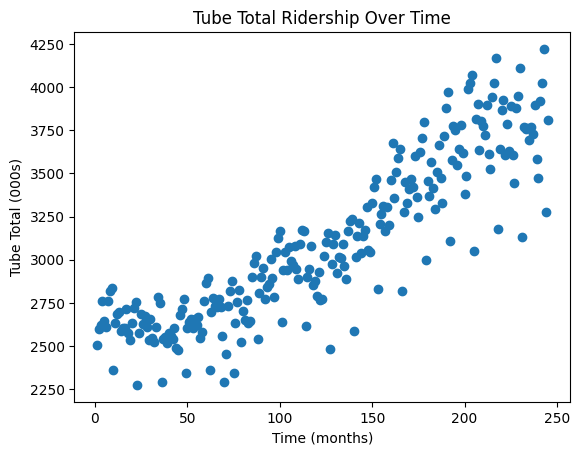

In [190]:
#Your code for scatterplot here

plt.scatter(xvals, yvals)
plt.xlabel('Time (months)')
plt.ylabel('Tube Total (000s)')
plt.title('Tube Total Ridership Over Time')
plt.show()

## 3b) Fit a linear model $f(x) = \beta_0 + \beta_1 x$ to the data

- Print the values of the regression coefficients $\beta_0, \beta_1$ determined using least-squares. 
- Plot the fitted model and the scatterplot on the same plot.
- Compute and print the **MSE** and the $R^2$ coefficient for the fitted model.

All numerical outputs should be displayed to three decimal places.

In [191]:
def polyreg(data_matrix, k):
    x_values = data_matrix[:, 0]
    y_values = data_matrix[:, 1]

    # Your code here
    # The function should return the the coefficient vector beta, the fit, and the vector of residuals
    all_ones = np.ones(np.shape(x_values))
    X = all_ones[:, np.newaxis]  # Start with the intercept term (column of ones)
    for i in range(1, k + 1):
        X = np.column_stack((X, x_values ** i))
    
    beta = np.linalg.lstsq(X, y_values, rcond=None)[0]
    fit = X @ beta
    residuals = y_values - fit

    return beta, fit, residuals

Coefficients (beta): [2367.38176648    5.93899012]


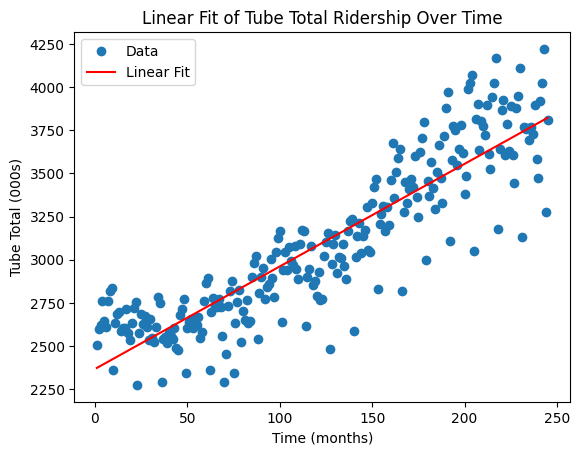

Mean Squared Error (MSE): 45323.63592122834
Sum of Squared Errors (SSE): 11104290.800700944


In [192]:
#Your code here
beta_lin, fit_lin, residuals = polyreg(np.column_stack((xvals, yvals)), 1)
print("Coefficients (beta):", beta_lin)
plt.plot(xvals, yvals, 'o', label='Data')
plt.plot(xvals, fit_lin, 'r-', label='Linear Fit')
plt.xlabel('Time (months)')
plt.ylabel('Tube Total (000s)')
plt.title('Linear Fit of Tube Total Ridership Over Time')
plt.legend()
plt.show()

MSE_lin = np.mean(residuals ** 2)
SSE_lin = np.sum(residuals ** 2)
print("Mean Squared Error (MSE):", MSE_lin)
print("Sum of Squared Errors (SSE):", SSE_lin)

## 3c)  Plotting the residuals

- Plot the residuals on a scatterplot
- Also plot the residuals over a short duration and comment on whether you can discern any periodic components.

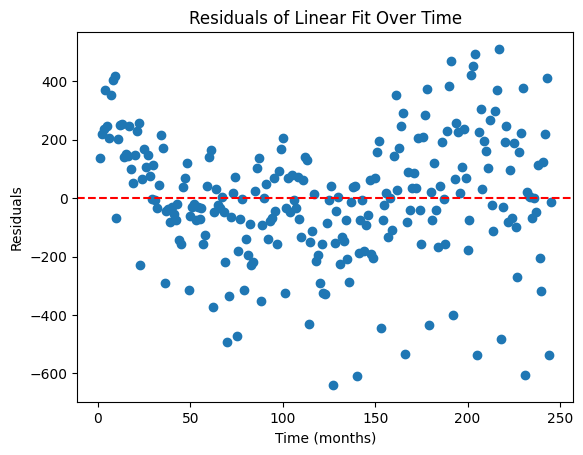

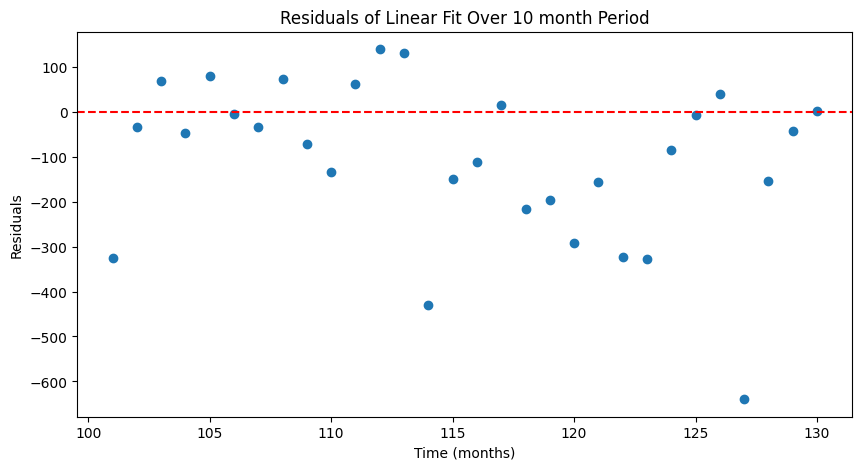

In [193]:
# Your code here
plt.plot(xvals, residuals, 'o')
plt.axhline(0, color='red', linestyle='--')
plt.xlabel('Time (months)')
plt.ylabel('Residuals')
plt.title('Residuals of Linear Fit Over Time')
plt.show()

# PLot residuals over a short time period to see if there are any patterns
plt.plot(xvals[100:130], residuals[100:130], 'o')
plt.gcf().set_size_inches(10, 5)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel('Time (months)')
plt.ylabel('Residuals')
plt.title('Residuals of Linear Fit Over 10 month Period')
plt.show()

< Comment on periodic components here >
There appears to be a bit of periodic motion but not a larger amount

### 3d) Periodogram

- Compute and plot the peridogram of the residuals. (Recall that the periodogram is the squared-magnitude of the DFT coefficients.)
- Identify the indices/frequencies for which the periogram value exceeds **50%** of the maximum. 


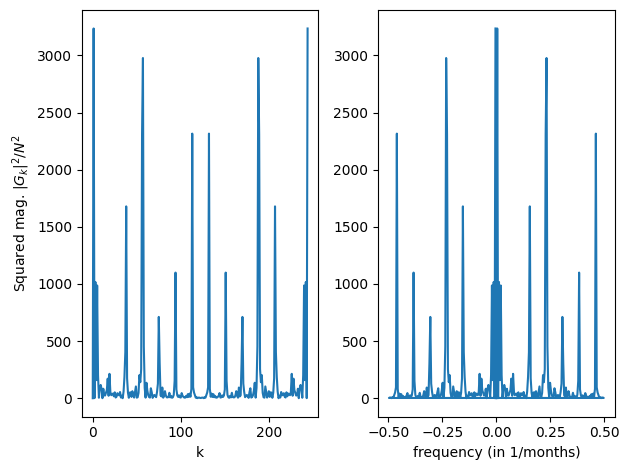

In [194]:
# Your code to compute and plot the periodogram

trunc_residuals = residuals  
N = np.size(trunc_residuals)
T = xvals[201] - xvals[200]  # This can be the time interval between any two successive values.

# Note that T is in months

# Compute the squared magnitudes of the DFT coefficients -- this is known as the "periodogram"
pgram = np.abs(np.fft.fft(trunc_residuals, N)/N)**2 #We normalize by N, but this is optional
indices = np.linspace(0, (N-1), num = N)
freqs_in_hz = np.fft.fftfreq(N)/T
freqs_in_rads = freqs_in_hz*2*math.pi

plt.subplot(121)
plt.plot(indices, pgram)
plt.xlabel('k')
plt.ylabel('Squared mag. $|G_k|^2/N^2$')
plt.subplot(122)
plt.plot(freqs_in_hz, pgram)
plt.xlabel('frequency (in 1/months)')  # Since units of T is months, the units of frequency is 1/months
plt.savefig('DFT_CO2.pdf', bbox_inches = 'tight')
plt.tight_layout()


In [195]:
# Your code to identify the indices for which the periodogram value exceeds 50% of the maximum

top_inds = indices[(pgram > 0.5*np.max(pgram))]
top_freqs_hz = freqs_in_hz[(pgram > 0.5*np.max(pgram))]
print('Top indices:', top_inds, ' Top frequencies in Hz:', top_freqs_hz)

Top indices: [  1.  38.  56.  57. 113. 132. 188. 189. 207. 244.]  Top frequencies in Hz: [ 0.00408163  0.15510204  0.22857143  0.23265306  0.46122449 -0.46122449
 -0.23265306 -0.22857143 -0.15510204 -0.00408163]


## 3e) To the residuals,  fit a model of the form  

$$ \beta_{1s} \sin(\omega_1 x) + \beta_{1c} \cos(\omega_1 x) + \beta_{2s} \sin(\omega_2 x) + \beta_{2c} \cos(\omega_2 x) + \ldots + \beta_{Ks} \sin(\omega_K x) + \beta_{Kc} \cos(\omega_K x).$$

The frequencies $\omega_1, \ldots, \omega_K$ in the model are those corresponding to the indices identified in Part 2c. (Hint: Each of the sines and cosines will correspond to one column in your X-matrix.)

- Print the values of the regression coefficients obtained using least-squares. 

All numerical outputs should be displayed to three decimal places.

Coefficients (beta): [  0.     50.778 -25.626 -27.003  30.814 -47.399  -7.79   36.191  40.829
  45.294  16.236  45.294 -16.236  36.191 -40.829 -47.399   7.79  -27.003
 -30.814  50.778  25.626]


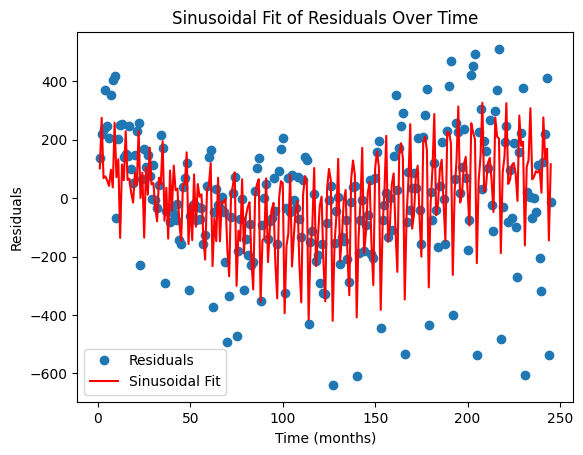

In [196]:
# Your code here
# Find the regression coefficinets for the sinusoids corresponding to the top frequencies
X = np.ones((N, 1))  # Start with the intercept term (column
for i in range(len(top_freqs_hz)):
    freq = top_freqs_hz[i]
    X = np.column_stack((X, np.cos(2 * np.pi * freq * xvals), np.sin(2 * np.pi * freq * xvals)))
beta_sin = np.linalg.lstsq(X, trunc_residuals, rcond=None)[0]
fit_sin = X @ beta_sin
residuals_sin = trunc_residuals - fit_sin

print("Coefficients (beta):", np.round(beta_sin, 3))

plt.plot(xvals, trunc_residuals, 'o', label='Residuals')
plt.plot(xvals, fit_sin, 'r-', label='Sinusoidal Fit')
plt.xlabel('Time (months)')
plt.ylabel('Residuals')
plt.title('Sinusoidal Fit of Residuals Over Time')
plt.legend()
plt.show()

### 3f) The combined fit
- Plot the combined fit together with a scatterplot of the data
- Compute and print the final **MSE** and $R^2$ coefficient. Comment on the improvement over the linear fit.

The combined fit, which corresponds to the full model

$$
f(x) = \beta_0 + \beta_1 x + \beta_{s1} \sin(\omega_1 x) + \beta_{c1} \cos(\omega_1 x) + \ldots + \beta_{sk} \sin(\omega_k x) + \beta_{ck} \cos(\omega_k x),
$$

can be obtained by adding the fits in parts 2b) and 2e).

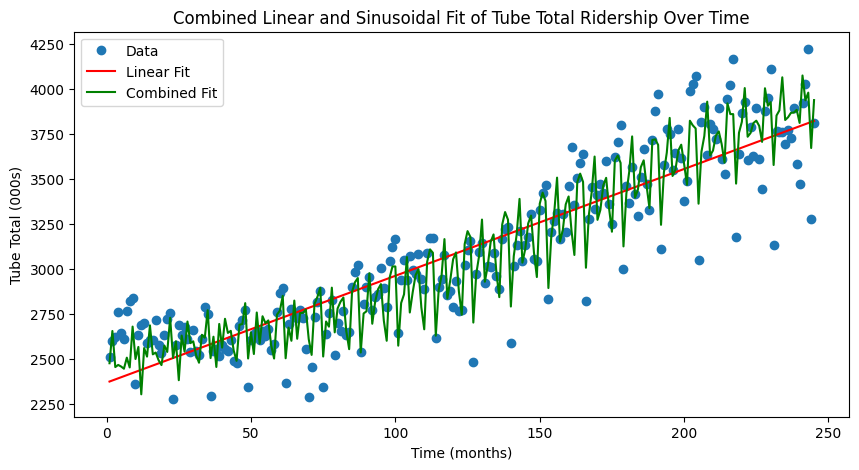

Mean Squared Error (MSE) of Linear Fit: 45323.63592122834
Mean Squared Error (MSE) of Combined Fit: 20297.50118777252
R^2 of Linear Fit: 0.7956113333574004
R^2 of Combined Fit: 0.9084676434354128


In [197]:
# Your code here
# Plot fit of the combined sinusoidal and linear fits
fit_combined = fit_lin + fit_sin
plt.figure(figsize=(10, 5))
plt.plot(xvals, yvals, 'o', label='Data')
plt.plot(xvals, fit_lin, 'r-', label='Linear Fit')
plt.plot(xvals, fit_combined, 'g-', label='Combined Fit')
plt.xlabel('Time (months)')
plt.ylabel('Tube Total (000s)')
plt.title('Combined Linear and Sinusoidal Fit of Tube Total Ridership Over Time')
plt.legend()
plt.show()

# Compute and print the MSE of the combined fit
residuals_combined = yvals - fit_combined
MSE_combined = np.mean(residuals_combined ** 2)
MSE_Lin = np.mean(residuals ** 2)
print("Mean Squared Error (MSE) of Linear Fit:", MSE_Lin)
print("Mean Squared Error (MSE) of Combined Fit:", MSE_combined)

# Compute R^2 for the linear fit and the combined fit
SS_0 = np.linalg.norm(yvals - np.mean(yvals)) ** 2
SS_res_lin = np.sum(residuals ** 2)
SS_res_combined = np.sum(residuals_combined ** 2)
SS_tot = np.sum((yvals - np.mean(yvals)) ** 2)
R2_lin = 1 - (SS_res_lin / SS_0)
R2_combined = 1 - (SS_res_combined / SS_0)
print("R^2 of Linear Fit:", R2_lin)
print("R^2 of Combined Fit:", R2_combined)


< Add comment on the improvement over the linear fit. >
Combined fit is a better models of the data, with reduced MSE and higher R^2